# Multi-group TIRT

How can we estimate group differences while sharing one questionnaire model?
This Thurstonian item response theory (TIRT) example uses 500 respondents from
the bundled empirical Big Five study and all 20 triplets. Balanced teaching
labels, randomly assigned to 250 respondents per group, demonstrate the
interface. This multi-group calibration shares measurement parameters while
estimating each group's population separately.

## Model

For person $p$ in group $g$, statement $i$ measures trait $t(i)$:

$$
\boldsymbol\theta_p\mid g\sim\mathcal N(\boldsymbol\mu_g,R_g),\qquad
m_{pi}=q_i a_i\theta_{p,t(i)}+\nu_i.
$$

Here $q_i$ is the supplied keying sign, $a_i>0$ the loading magnitude and
$\nu_i$ a global statement effect. For the first-statement preference code,

$$
P(Y_{pij}=1)=\Phi\left(
\frac{m_{pi}-m_{pj}-\gamma_{bij}}{\sqrt{v_i+v_j}}
\right),\qquad v_i=\psi_i^2.
$$

$Y_{pij}=1$ means that person $p$ preferred statement $i$ to statement $j$.
$\Phi$ is the standard normal cumulative distribution function;
$\gamma_{bij}$ is the pair cutpoint and $v_i$ is residual variance.

All measurement parameters are shared across groups. Each group has its own
trait correlation matrix $R_g$ and mean $\boldsymbol\mu_g$. Rankings supply
pair comparisons; their product is a **composite target**, not the joint
probability of an entire ranking. Shared statements induce dependencies that
these pair factors do not jointly model.

Native defaults are $a_i\sim\operatorname{LogNormal}(0,0.5)$,
$\gamma_{bij}\sim\mathcal N(0,1)$, free $v_i\sim\operatorname{HalfNormal}(1)$,
and $\nu_i\mid v_i\sim\mathcal N(0,v_i)$ (Normal's second argument here is
variance). The implementation samples statement effects noncentrally.
Free group means have independent Normal(0, 1) priors and each $R_g$ has an
LKJ(1) prior. The printed summary below records the resolved declarations.

## Identification

Group A's means are fixed at zero, and both groups have unit marginal trait
standard deviations (SDs). Each triplet's residual reference variance is fixed at 0.5 by preparation;
keying fixes trait orientation. Shared measurement parameters put Group B's
means on Group A's scale. These assumptions permit comparisons; they do not
test measurement invariance. A cutpoint can absorb a statement-effect contrast,
so their separate estimates depend on the priors. Read uncertainty and mixing
before interpreting either. [TIRT model notes](../models/tirt.md) give the
response coding, reference rules and original references.

In [2]:
from itertools import combinations

import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import pyfcirt as fc

## 1. Prepare one group label per person

The loader samples without replacement with seed 42, keeps complete block design
and preserves the source row order and missing responses. The independent label
seed fixes one balanced assignment aligned by `person_id`. Save this table with
any reported fit. The empirical source has no group demographics.

In [3]:
study = fc.load_example("carelessness_big_five", model=fc.TIRT(), n_persons=500, random_seed=42)
people = study.data.responses.frame[["person_id"]].drop_duplicates().reset_index(drop=True)
people["group"] = (
    pd.Series(["Group A"] * 250 + ["Group B"] * 250)
    .sample(frac=1, random_state=20261114)
    .reset_index(drop=True)
)
display(people.head())
display(people.groupby("group").size().rename("n_people").to_frame())
display(study.metadata["selection"])

,person_id,group
0,3,Group B
1,4,Group B
2,6,Group A
3,7,Group A
4,10,Group B


,n_people
group,
Group A,250
Group B,250


{'n_persons': 500,
 'stored_n_persons': 1169,
 'resource': 'n1169.json.gz',
 'policy': 'seeded sample without replacement; source row order and complete design retained',
 'random_seed': 42}

In [4]:
population = fc.PopulationSpec(
    group="group", theta_residual_scale="unit", reference_group="Group A"
)
prepared = fc.PreparedInputs.from_inputs(study.data, population=population, person_data=people)
grouped = fc.Model(prepared)
print(grouped.summary(details=True))
display(fc.data_coverage(grouped, details=True))

Model: TIRT
500 people, 5 traits, 20 blocks, 60 statements
Observations: 29,360 pair comparisons
Measurements:
  rank: 20 blocks, size=3, link=probit
    IDs: ('B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B10', 'B11', 'B12', 'B13', 'B14', 'B15', 'B16', 'B17', 'B18', 'B19', 'B20')
Population:
  theta ~ MvNormal(mu=population_mean[group], cov=R)
  Groups: ('Group B', 'Group A'); reference='Group A'
  R [2 x 5 x 5] ~ LKJCorr(n=5, eta=1)
  population_mean [5] ~ Normal(mu=0, sigma=1)
  parameterization=centered; theta_residual_scale='unit'
Priors:
    loading [60] ~ LogNormal(mu=0, sigma=0.5)
      Blocks/items: ('B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B10', 'B11', 'B12', 'B13', 'B14', 'B15', 'B16', 'B17', 'B18', 'B19', 'B20')
    statement_effect [60] ~ Normal(mu=0, sigma=sqrt(residual_variance))
      Blocks/items: ('B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B10', 'B11', 'B12', 'B13', 'B14', 'B15', 'B16', 'B17', 'B18', 'B19',

,n_blocks,link,n_categories,size,n_persons,n_answered,n_missing,n_refused,n_not_administered,n_obs
model_response_format,,,,,,,,,,
TIRT / rank,20,probit,2,3,500,9828,172,0,0,29360


## 2. Fit the multi-group model

Four centered-theta chains use 3,000 warmup iterations and retain 3,000 draws each,
with target acceptance 0.8 and diagonal mass adaptation. The tables and figures
below use the saved GPU fit.


In [6]:
grouped.fit(
    chains=4,
    tune=3000,
    draws=3000,
    target_accept=0.8,
    random_seed=44,
    nuts_sampler_kwargs={"is_mass_matrix_diagonal": True},
)

/root/autodl-tmp/pyfcirt-group-33631-20261117-01/source/pyfcirt/model.py:379: FutureWarning: `nuts_sampler_kwargs` is deprecated. Pass NUTS keyword arguments via the `nuts={...}` argument to `pm.sample`.
  sampled = pm.sample(var_names=selected, idata_kwargs=idata_kwargs, **sample_kwargs)


NUTS[blackjax]: [_parameter_0_raw, _parameter_2_raw, _parameter_1_raw_raw, _parameter_3_raw, _parameter_4_raw, _parameter_5_raw, _parameter_6_raw, _parameter_7_raw, _parameter_8_raw, _parameter_9_raw, _parameter_10_raw, _parameter_11_raw, _parameter_12_raw, _parameter_13_raw, _parameter_14_raw, _parameter_15_raw, _parameter_16_raw, _parameter_17_raw, _parameter_18_raw, _parameter_19_raw, _parameter_20_raw, _parameter_21_raw, _parameter_22_raw, _parameter_23_raw, _parameter_24_raw, theta]


<xarray.DataTree>
Group: /
│   Attributes:
│       inference_method:                     mcmc
│       posterior_run_id:                     5dcd27074a974452897d9e1a92c11412
│       sampling_draws:                       3000
│       sampling_tune:                        3000
│       sampling_chains:                      4
│       sampling_nuts_sampler:                blackjax
│       sampling_target_accept:               0.8
│       sampling_random_seed:                 44
│       sampling_compute_convergence_checks:  0
├── Group: /design
│       Dimensions:                                (unit: 20, statement: 60, pair: 60,
│                                                   obs: 29360,
│                                                   observation_source: 29360,
│                                                   person: 500, block: 20,
│                                                   position: 3, item: 0, trait: 5,
│                                                   trait_aux: 5, population_group: 2)
│       Coordinates:
│         * unit                                   (unit) int64 160B 0 1 2 ... 17 18 19
│           unit_channel                           (unit) <U2 160B 'fc' 'fc' ... 'fc'
│         * statement                              (statement) int64 480B 0 1 ... 58 59
│           statement_label                        (statement) object 480B 'B01_1' .....
│           statement_channel                      (statement) <U2 480B 'fc' ... 'fc'
│         * person                                 (person) object 4kB 3 4 ... 1167 1169
│         * block                                  (block) object 160B 'B01' ... 'B20'
│         * item                                   (item) object 0B 
│         * trait                                  (trait) object 40B 'n' 'e' ... 'o'
│         * trait_aux                              (trait_aux) object 40B 'n' ... 'o'
│         * population_group                       (population_group) object 16B 'Gro...
│       Dimensions without coordinates: pair, obs, observation_source, position
│       Data variables: (12/31)
│           unit_model                             (unit) <U4 320B 'TIRT' ... 'TIRT'
│           unit_response_format                   (unit) <U4 320B 'rank' ... 'rank'
│           unit_block                             (unit) int64 160B 0 1 2 ... 17 18 19
│           unit_item                              (unit) int64 160B -1 -1 -1 ... -1 -1
│           statement_trait                        (statement) int64 480B 0 1 2 ... 2 1
│           statement_keying                       (statement) float64 480B 1.0 ... 1.0
│           ...                                     ...
│           person_group                           (person) int64 4kB 0 0 1 1 ... 1 1 0
│           fc_statement                           (block, position) int64 480B 0 ... 59
│           fc_size                                (block) int64 160B 3 3 3 3 ... 3 3 3
│           item_q                                 (item, trait) bool 0B 
│           unit_scale_kind                        (unit) <U4 320B 'none' ... 'none'
│           unit_scale_higher_prefers              (unit) <U5 400B 'first' ... 'first'
│       Attributes:
│           parameter_contract:  1
├── Group: /parameter_uses
│       Dimensions:        (parameter_use: 240)
│       Dimensions without coordinates: parameter_use
│       Data variables:
│           kind           (parameter_use) <U17 16kB 'loading' 'loading' ... 'cutpoint'
│           entry_index    (parameter_use) int64 2kB 0 1 2 0 1 2 0 ... 57 58 59 57 58 59
│           unit_index     (parameter_use) int64 2kB 0 0 0 0 0 0 0 ... 19 19 19 19 19 19
│           key            (parameter_use) <U17 16kB 'loading_magnitude' ... 'cutpoints'
│           slot_position  (parameter_use) int64 2kB 0 1 2 0 1 2 0 1 ... 1 2 0 1 2 0 1 2
│           trait_index    (parameter_use) int64 2kB 0 1 2 0 1 2 0 ... 1 3 2 1 -1 -1 -1
├── Group: /categories
│       Dimensions:           (category_entry: 0)
│

In [6]:
posterior = grouped.idata["posterior"].to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    posterior_summary = az.summary(
        posterior, kind="all", fmt="xarray", ci_kind="hdi", ci_prob=0.95, round_to="none"
    )

# Keep the prepared constraints, including diagonals with floating-point noise.
for layout in grouped.prepared.parameters:
    if layout.kind in posterior_summary:
        fixed = xr.DataArray(
            np.isfinite(layout.fixed),
            dims=layout.dims,
            coords={dim: posterior[dim] for dim in layout.dims},
        )
        posterior_summary[layout.kind] = posterior_summary[layout.kind].where(
            ~fixed | posterior_summary.summary.isin(["mean", "sd", "hdi95_lb", "hdi95_ub"])
        )

# Convert each labelled family separately; retain its original coordinate columns.
summary = pd.concat(
    [
        values.expand_dims(parameter=[name]).to_series().unstack("summary").reset_index()
        for name, values in posterior_summary.data_vars.items()
    ],
    ignore_index=True,
)
identity_columns = summary.columns.difference(posterior_summary.summary.values, sort=False)
summary = summary.loc[:, [*identity_columns, *posterior_summary.summary.values]]
overview = pd.Series(
    {
        "Maximum R-hat": summary.r_hat.max(),
        "Minimum bulk ESS": summary.ess_bulk.min(),
        "Minimum tail ESS": summary.ess_tail.min(),
        "Divergences": int(grouped.idata["sample_stats"]["diverging"].sum().item()),
    }
)
family_diagnostics = summary.groupby("parameter", sort=False).agg(
    max_r_hat=("r_hat", "max"),
    min_bulk_ess=("ess_bulk", "min"),
    min_tail_ess=("ess_tail", "min"),
    max_mcse_mean=("mcse_mean", "max"),
)
display(overview.to_frame("value").round(3))
display(family_diagnostics.round(3))
display(summary.sort_values("r_hat", ascending=False).head(10).dropna(axis=1, how="all").round(3))

,value
Maximum R-hat,1.025
Minimum bulk ESS,151.586
Minimum tail ESS,221.747
Divergences,0.000


,max_r_hat,min_bulk_ess,min_tail_ess,max_mcse_mean
parameter,,,,
theta,1.021,172.023,247.002,0.074
loading,1.025,151.586,232.495,0.024
residual_variance,1.021,158.533,286.812,0.064
statement_effect,1.002,3959.111,2968.038,0.010
cutpoint,1.001,7423.803,5746.944,0.008
trait_correlation,1.024,158.230,221.747,0.015
population_mean,1.002,1534.220,2992.897,0.003
covariance,1.024,158.230,221.747,0.015


summary,parameter,person,trait,loading_id,residual_variance_id,population_group,trait_aux,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
2558,loading,NaN,NaN,58.0,NaN,NaN,NaN,0.300,0.146,0.105,0.614,151.586,263.343,1.025,0.013,0.006
2554,loading,NaN,NaN,54.0,NaN,NaN,NaN,0.517,0.183,0.224,0.897,157.006,284.817,1.025,0.015,0.007
2754,trait_correlation,NaN,a,NaN,NaN,Group B,o,0.048,0.146,-0.212,0.340,174.998,316.109,1.024,0.011,0.003
2822,covariance,NaN,o,NaN,NaN,Group B,a,0.048,0.146,-0.212,0.340,174.998,316.109,1.024,0.011,0.003
2814,covariance,NaN,a,NaN,NaN,Group B,o,0.048,0.146,-0.212,0.340,174.998,316.109,1.024,0.011,0.003
2762,trait_correlation,NaN,o,NaN,NaN,Group B,a,0.048,0.146,-0.212,0.340,174.998,316.109,1.024,0.011,0.003
1252,theta,559.0,a,NaN,NaN,NaN,NaN,-0.435,0.856,-2.036,1.276,187.044,318.347,1.021,0.064,0.019
2562,residual_variance,NaN,NaN,NaN,2.0,NaN,NaN,0.901,0.740,0.001,2.399,158.533,286.812,1.021,0.064,0.032
2523,loading,NaN,NaN,23.0,NaN,NaN,NaN,0.975,0.294,0.385,1.470,163.912,232.495,1.021,0.024,0.009
2503,loading,NaN,NaN,3.0,NaN,NaN,NaN,0.404,0.161,0.156,0.735,180.436,348.899,1.021,0.012,0.006


The screen covers every retained family, including individual traits, shared
measurement parameters, group means and correlations. R-hat compares the chains;
values near 1 indicate closer agreement. Effective sample size (ESS) describes
how much independent information the correlated draws contain, and Monte Carlo
standard error (MCSE) measures simulation error in a reported estimate.
Fixed means, residual references and correlation diagonals have NA sampling
diagnostics because they were constrained. The full unrounded table is retained
with the run.

Formal examples require maximum R-hat strictly below 1.05. The separate 1.01/400
precision screen and all Monte Carlo error reporting remain available.


## 3. Inspect shared measurement and population coefficients

Print all measurement coefficients, group means and population moments.
`loading` reports $a_i$, positive under this fit's default prior. Keying is
applied separately: the utility coefficient is $q_i a_i$. Larger $a_i$ gives a
stronger trait contribution. A larger cutpoint shifts preference toward the second statement
under this coding. `statement_effect` is requested explicitly because ordinary
measurement summaries omit it. Reference values appear under `mean`; their
uncertainty and diagnostics remain NA. These measurement entries are shared
across groups. The population tables retain their group and trait labels.
The trait codes are `n` (neuroticism), `e` (extraversion), `a` (agreeableness),
`c` (conscientiousness) and `o` (openness).
The complete tables below can be scrolled within the output panel.

In [8]:
measurement = fc.coef(
    grouped,
    kind="all",
    round_to=2,
)
population_coefficients = fc.coef(grouped, component="regression", kind="all", round_to=2)
moments = fc.trait_summary(grouped, by_group=True, kind="all", round_to=2)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    for coefficients in (measurement, population_coefficients):
        display(
            coefficients.style.format(precision=2, na_rep="NA")
            .format_index(na_rep="")
            .set_table_attributes('class="dataframe table table-sm"')
        )
    for name, values in moments.data_vars.items():
        print(name)
        display(
            values.to_series()
            .unstack("summary")
            .style.format(precision=2, na_rep="NA")
            .format_index(na_rep="")
            .set_table_attributes('class="dataframe table table-sm"')
        )

mean 
 sd 
 hdi95_lb 
 hdi95_ub 
 ess_bulk 
 ess_tail 
 r_hat 
 mcse_mean 
 mcse_sd 
 
 
 population_group 
 trait 
 parameter 
   
   
   
   
   
   
   
   
   
 
 
 
 
 Group B 
 n 
 Intercept 
 -0.05 
 0.10 
 -0.25 
 0.15 
 1575.84 
 2992.90 
 1.00 
 0.00 
 0.00 
 
 
 e 
 Intercept 
 0.03 
 0.10 
 -0.16 
 0.22 
 1534.22 
 3452.42 
 1.00 
 0.00 
 0.00 
 
 
 a 
 Intercept 
 0.05 
 0.11 
 -0.18 
 0.26 
 1798.88 
 3731.25 
 1.00 
 0.00 
 0.00 
 
 
 c 
 Intercept 
 0.10 
 0.10 
 -0.10 
 0.30 
 2104.57 
 3949.01 
 1.00 
 0.00 
 0.00 
 
 
 o 
 Intercept 
 -0.02 
 0.11 
 -0.23 
 0.19 
 1690.79 
 3451.12 
 1.00 
 0.00 
 0.00 
 
 
 Group A 
 n 
 Intercept 
 0.00 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 
 
 e 
 Intercept 
 0.00 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 
 
 a 
 Intercept 
 0.00 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 
 
 c 
 Intercept 
 0.00 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 
 
 o 
 Intercept 
 0.00 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA 
 NA

trait_mean


trait_sd


trait_correlation


## 4. Compare group means directly

Subtract the reference mean within each draw. Because Group A is fixed at zero,
these are also Group B's means, in common latent SD units. The 95% highest-density intervals (HDIs) summarize
posterior uncertainty under this model and its composite target. Compare each
interval with zero and inspect its MCSE.
Dots show posterior means; thick and thin bars show 50% and 95% HDIs.


,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mean_difference[n],-0.049,0.101,-0.246,0.152,1575.837,2992.897,1.002,0.003,0.001
mean_difference[e],0.034,0.098,-0.161,0.221,1534.220,3452.416,1.001,0.003,0.001
mean_difference[a],0.046,0.113,-0.182,0.264,1798.880,3731.250,1.002,0.003,0.001
mean_difference[c],0.096,0.103,-0.103,0.297,2104.575,3949.005,1.000,0.002,0.001
mean_difference[o],-0.023,0.107,-0.230,0.187,1690.794,3451.116,1.001,0.003,0.001


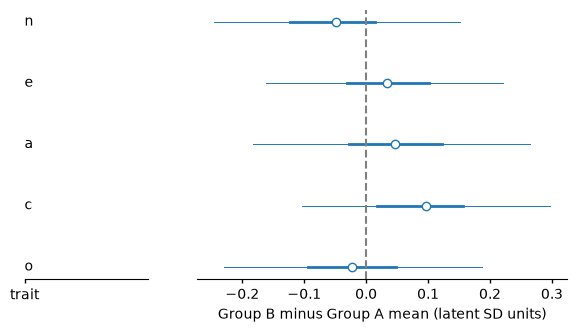

In [9]:
means = posterior["population_mean"]
mean_difference = (
    means.sel(population_group="Group B", drop=True)
    - means.sel(population_group="Group A", drop=True)
).to_dataset(name="mean_difference")
mean_results = az.summary(mean_difference, kind="all", ci_kind="hdi", ci_prob=0.95, round_to="none")
display(mean_results.round(3))
azp.plot_forest(
    mean_difference,
    combined=True,
    ci_kind="hdi",
    ci_probs=(0.5, 0.95),
    point_estimate="mean",
    labels=["trait"],
    backend="matplotlib",
    figure_kwargs={"figsize": (7, 3.5)},
)
plt.gcf().axes[-1].axvline(0, color="0.5", linestyle="--")
plt.gcf().axes[-1].set_xlabel("Group B minus Group A mean (latent SD units)")
plt.show()

## 5. Compare trait correlations within draws

Separate group intervals do not answer whether the correlations differ.
Compute Group B minus Group A in each posterior draw, retaining dependence
between the estimates. Each row below is a distinct trait pair; diagonal ones
are fixed and excluded. Values near zero indicate similar modeled correlations.
These are population trait correlations, not correlations of posterior-mean scores.

,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
correlation_difference[n / e],0.043,0.088,-0.132,0.214,9411.222,9977.634,1.001,0.001,0.001
correlation_difference[n / a],-0.060,0.107,-0.262,0.156,6176.320,4468.335,1.001,0.001,0.001
correlation_difference[n / c],0.149,0.118,-0.095,0.368,7615.657,8803.056,1.000,0.001,0.001
correlation_difference[n / o],0.183,0.122,-0.056,0.421,7597.006,8455.814,1.000,0.001,0.001
correlation_difference[e / a],0.038,0.103,-0.162,0.243,1143.558,2837.837,1.002,0.003,0.001
correlation_difference[e / c],-0.146,0.119,-0.381,0.084,3135.966,6589.405,1.001,0.002,0.001
correlation_difference[e / o],0.061,0.110,-0.158,0.271,7424.482,9039.335,1.000,0.001,0.001
correlation_difference[a / c],-0.090,0.143,-0.364,0.189,908.455,1849.824,1.005,0.005,0.001
correlation_difference[a / o],-0.095,0.143,-0.364,0.191,964.512,2091.814,1.005,0.005,0.001
correlation_difference[c / o],-0.202,0.125,-0.436,0.055,6092.425,7576.065,1.001,0.002,0.001


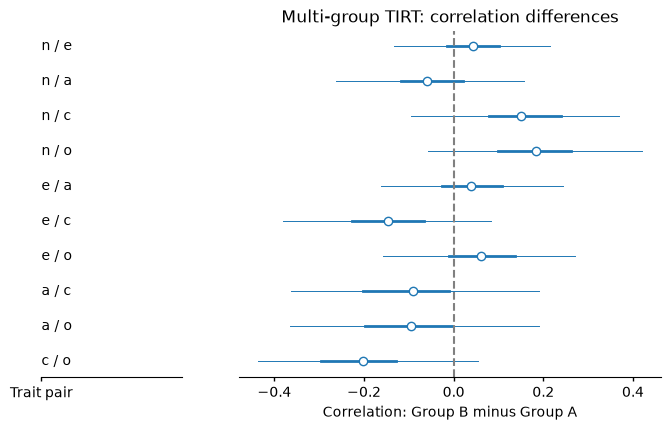

In [10]:
correlation = posterior["trait_correlation"]
differences, labels = [], []
for first, second in combinations(correlation.trait.values, 2):
    values = correlation.sel(trait=first, trait_aux=second)
    differences.append(
        values.sel(population_group="Group B", drop=True)
        - values.sel(population_group="Group A", drop=True)
    )
    labels.append(f"{first} / {second}")
contrast = xr.concat(differences, dim=pd.Index(labels, name="pair")).reset_coords(drop=True)
correlation_difference = contrast.to_dataset(name="correlation_difference")
correlation_results = az.summary(
    correlation_difference, kind="all", ci_kind="hdi", ci_prob=0.95, round_to="none"
)
display(correlation_results.round(3))
azp.plot_forest(
    correlation_difference,
    combined=True,
    ci_kind="hdi",
    ci_probs=(0.5, 0.95),
    point_estimate="mean",
    labels=["pair"],
    backend="matplotlib",
    figure_kwargs={"figsize": (8, 4.5)},
)
plt.gcf().axes[-1].axvline(0, color="0.5", linestyle="--")
plt.gcf().axes[-1].set_xlabel("Correlation: Group B minus Group A")
plt.gcf().axes[-1].set_title("Multi-group TIRT: correlation differences")
plt.gcf().axes[0].set_xticks([0], labels=["Trait pair"])
plt.show()

The saved fit meets the formal R-hat < 1.05 screen (maximum 1.025); it does not meet the separate 1.01/400 precision screen. Minimum bulk/tail ESS are 152/222, with 0 divergences. Group labels are balanced teaching assignments, not empirical demographics; interpret the displayed intervals under this model and its composite response target.